## Day 27 — Random Forests, Bagging, and Responsible Interpretation

## Part A — Understand the instability you are fixing 

## TASK 01 — Bootstrap samples by hand 

In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# 1. Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# 2. Normalize column names
df.columns = df.columns.str.strip().str.lower()

# 3. Display dataset information
print("Dataset shape:", df.shape)
print("Total rows:", len(df))

# 4. Calculate survival rate
print("Survival rate:", round(df["survived"].mean() * 100, 2), "%")

# 5. Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# 6. Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower().map({
        "male": 1,
        "female": 0
    })
)

# 7. Impute missing age using Pclass and Sex groups
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)

# Fill any remaining missing age values with overall median
df["age"] = df["age"].fillna(df["age"].median())

# 8. Fill missing fare values with median
df["fare"] = df["fare"].fillna(df["fare"].median())

# 9. Select required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

X = df[features]
y = df[target]

# 10. Check cleaned data
print("\nMissing values after cleaning:")
print(X.isnull().sum())

print("\nFeature columns:")
print(X.columns.tolist())

# 11. Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 12. Display split information
print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining survival rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting survival rate:")
print(round(y_test.mean() * 100, 2), "%")

print("\nTitanic dataset preparation completed successfully!")


Dataset shape: (1000, 7)
Total rows: 1000
Survival rate: 44.0 %

Missing values before cleaning:
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Missing values after cleaning:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Feature columns:
['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']

Training rows: 800
Testing rows: 200

Training survival rate:
44.0 %

Testing survival rate:
44.0 %

Titanic dataset preparation completed successfully!
Original Training Rows: 800
Bootstrap Rows: 800
Unique Original Rows: 502
Rows Never Selected: 298
Example Row Selected More Than Once: 57
Number of Times Selected: 5


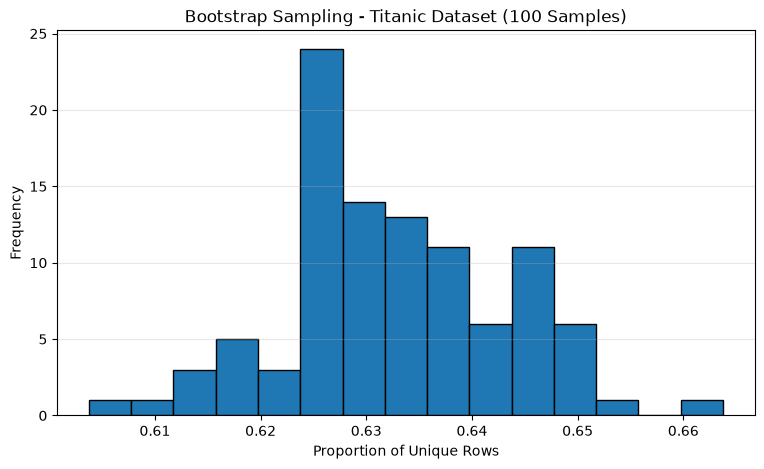

Average Unique Row Proportion: 0.6325624999999999


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Display dataset information
print("Dataset shape:", df.shape)
print("Total rows:", len(df))

# Calculate survival rate
print("Survival rate:", round(df["survived"].mean() * 100, 2), "%")

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower().map({
        "male": 1,
        "female": 0
    })
)

# Impute missing age using Pclass and Sex groups
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)

# Fill any remaining missing age values with overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

X = df[features]
y = df[target]

# Check cleaned data
print("\nMissing values after cleaning:")
print(X.isnull().sum())

print("\nFeature columns:")
print(X.columns.tolist())

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display split information
print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining survival rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting survival rate:")
print(round(y_test.mean() * 100, 2), "%")

print("\nTitanic dataset preparation completed successfully!")


# 1. Bootstrap sampling function
def bootstrap_sample(X, y, rng):
    indices = rng.integers(0, len(X), size=len(X))

    X_sample = X.iloc[indices].copy()
    y_sample = y.iloc[indices].copy()

    return X_sample, y_sample


# 2. Create one random number generator
rng = np.random.default_rng(7)


# 3. Draw  one bootstrap sample
X_boot, y_boot = bootstrap_sample(X_train, y_train, rng)


# 4. Calculate bootstrap statistics
original_rows = len(X_train)
bootstrap_rows = len(X_boot)

# Count unique original row indices
unique_rows = X_boot.index.nunique()

# Count rows never selected
missing_rows = original_rows - unique_rows

# Find one original row selected more than once
duplicate_counts = X_boot.index.value_counts()
duplicate_rows = duplicate_counts[duplicate_counts > 1]

example_duplicate = duplicate_rows.index[0]


# 5. Print results
print("Original Training Rows:", original_rows)
print("Bootstrap Rows:", bootstrap_rows)
print("Unique Original Rows:", unique_rows)
print("Rows Never Selected:", missing_rows)
print("Example Row Selected More Than Once:", example_duplicate)
print("Number of Times Selected:", duplicate_rows.iloc[0])


# 6. Repeat bootstrap sampling 100 times
unique_proportions = []

for i in range(100):
    X_sample, y_sample = bootstrap_sample(X_train, y_train, rng)

    proportion = X_sample.index.nunique() / len(X_train)

    unique_proportions.append(proportion)


# 7. Plot histogram
plt.figure(figsize=(9, 5))

plt.hist(unique_proportions, bins=15, edgecolor="black")

plt.xlabel("Proportion of Unique Rows")
plt.ylabel("Frequency")
plt.title("Bootstrap Sampling - Titanic Dataset (100 Samples)")

plt.grid(axis="y", alpha=0.3)
plt.show()


# 8. Average unique-row proportion
print(
    "Average Unique Row Proportion:",
    np.mean(unique_proportions)
)


## TASK 02 — Make five trees disagree 

In [ ]:

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Display dataset information
print("Dataset shape:", df.shape)
print("Total rows:", len(df))

# Calculate survival rate
print("Survival rate:", round(df["survived"].mean() * 100, 2), "%")

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower().map({
        "male": 1,
        "female": 0
    })
)

# Impute missing age using Pclass and Sex groups
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)

# Fill any remaining missing age values with overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

X = df[features]
y = df[target]

# Check cleaned data
print("\nMissing values after cleaning:")
print(X.isnull().sum())

print("\nFeature columns:")
print(X.columns.tolist())

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display split information
print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining survival rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting survival rate:")
print(round(y_test.mean() * 100, 2), "%")

print("\nTitanic dataset preparation completed successfully!")


# Bootstrap sampling function
def bootstrap_sample(X, y, rng):
    indices = rng.integers(0, len(X), size=len(X))

    X_sample = X.iloc[indices].copy()
    y_sample = y.iloc[indices].copy()

    return X_sample, y_sample


# 1. Create one random number generator
rng = np.random.default_rng(7)


# 2. Train five Decision Trees using different bootstrap samples
trees = []

for i in range(5):

    # Create a bootstrap sample
    X_sample, y_sample = bootstrap_sample(X_train, y_train, rng)

    # Create Decision Tree with maximum depth 5
    tree = DecisionTreeClassifier(
        max_depth=5,
        random_state=7 + i
    )

    # Train the tree
    tree.fit(X_sample, y_sample)

    trees.append(tree)


# 3. Select the same first 20 test passengers
X_first20 = X_test.iloc[:20]
y_first20 = y_test.iloc[:20]


# 4. Get predictions from all five trees
predictions = {}

for i, tree in enumerate(trees):
    predictions[f"Tree_{i+1}"] = tree.predict(X_first20)


# 5. Create a DataFrame
results = pd.DataFrame(predictions, index=X_first20.index)

# Count how many trees predict survival
results["Survive_Votes"] = (results[
    ["Tree_1", "Tree_2", "Tree_3", "Tree_4", "Tree_5"]] == 1).sum(axis=1)

# Count how many trees predict non-survival
results["Not_Survive_Votes"] = 5 - results["Survive_Votes"]

# Forest-style majority prediction
results["Forest_Prediction"] = (
    results["Survive_Votes"] >= 3
).astype(int)

# Add actual Titanic survival labels
results["True_Label"] = y_first20


# 6. Display complete prediction table
print("Predictions for First 20 Titanic Passengers:")
print(results.to_string())


# 7. Identify passengers where trees disagree
tree_columns = ["Tree_1", "Tree_2", "Tree_3", "Tree_4", "Tree_5"]

disagreement = results[tree_columns].nunique(axis=1) > 1

disagree_passengers = results[disagreement]


print("\nPassengers Where Trees Disagree:")

for passenger_index, row in disagree_passengers.iterrows():

    survive = row["Survive_Votes"]
    not_survive = row["Not_Survive_Votes"]

    print(
        f"Passenger Index {passenger_index}: "
        f"{survive} survive / {not_survive} do not survive"
    )


# 8. Calculate disagreement percentage
disagree_count = disagreement.sum()

disagree_percentage = (disagree_count / len(results)) * 100

print("\nTotal Passengers:", len(results))
print("Passengers With Disagreement:", disagree_count)

print(
    "Disagreement Percentage:",
    round(disagree_percentage, 2), "%"
)


Dataset shape: (1000, 7)
Total rows: 1000
Survival rate: 44.0 %

Missing values before cleaning:
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Missing values after cleaning:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Feature columns:
['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']

Training rows: 800
Testing rows: 200

Training survival rate:
44.0 %

Testing survival rate:
44.0 %

Titanic dataset preparation completed successfully!
Predictions for First 20 Titanic Passengers:
     Tree_1  Tree_2  Tree_3  Tree_4  Tree_5  Survive_Votes  Not_Survive_Votes  Forest_Prediction  True_Label
262       1       1       1       1       1              5                  0                  1           1
819       0       1       0       0       0              1                  4                  0           0
997       0       1       1       0       1              3     

1\. Why can five trees disagree?\
Each tree is trained on a different bootstrap sample, so each learns different patterns and makes different predictions.

2\. Is disagreement always bad?\
No. Disagreement shows uncertainty in predictions and helps identify passengers who are difficult to classify.

3\. Which prediction is less fragile: one tree or a 5–0 vote? Why?\
A 5–0 vote is less fragile because all five trees agree, making the prediction more consistent and reliable than a single tree's prediction.

## Part B — Build bagging and Random Forests 

## TASK 03 — Implement a bagged forest manually

Dataset shape: (1000, 7)
Total rows: 1000
Survival rate: 44.0 %

Missing values before cleaning:
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Missing values after cleaning:
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Feature columns:
['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']

Training rows: 800
Testing rows: 200

Training survival rate:
44.0 %

Testing survival rate:
44.0 %

Titanic dataset preparation completed successfully!
Model Performance Comparison:
      Model  Accuracy  ROC-AUC
  100 Trees      0.76 0.880175
Single Tree      0.75 0.811029


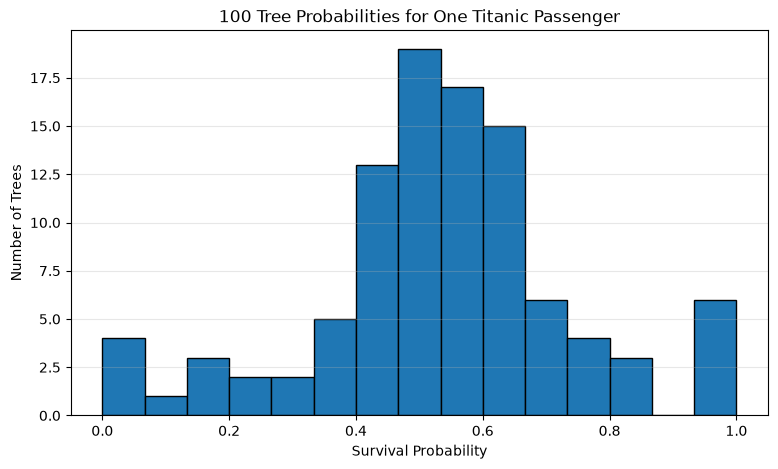

Passenger Index: 98
Average Survival Probability: 0.535
Actual Survival: 1


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

# Load the Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Display dataset information
print("Dataset shape:", df.shape)
print("Total rows:", len(df))

# Calculate survival rate
print("Survival rate:", round(df["survived"].mean() * 100, 2), "%")

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Create numeric sex_male feature
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower().map({
        "male": 1,
        "female": 0
    })
)

# Impute missing age using Pclass and Sex groups
df["age"] = df.groupby(
    ["pclass", "sex_male"]
)["age"].transform(
    lambda group: group.fillna(group.median())
)

# Fill any remaining missing age values with overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Select required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

X = df[features]
y = df[target]

# Check cleaned data
print("\nMissing values after cleaning:")
print(X.isnull().sum())

print("\nFeature columns:")
print(X.columns.tolist())

# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display split information
print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining survival rate:")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting survival rate:")
print(round(y_test.mean() * 100, 2), "%")

print("\nTitanic dataset preparation completed successfully!")



# 1. Create random number generator
rng = np.random.default_rng(7)


# 2. Train 100 Decision Trees
trees = []

for i in range(100):

    # Create fresh bootstrap sample
    X_sample, y_sample = bootstrap_sample(X_train, y_train, rng)

    # Create depth-5 Decision Tree
    tree = DecisionTreeClassifier(
        max_depth=5,
        random_state=7 + i
    )

    # Train the tree
    tree.fit(X_sample, y_sample)

    # Store the trained tree
    trees.append(tree)


# 3. Collect predictions from all 100 trees
# 4. Collect survival probabilities
tree_probabilities = np.array([
    tree.predict_proba(X_test)[:, 1] for tree in trees
])

tree_predictions = np.array([
    tree.predict(X_test) for tree in trees
])

# 5. Calculate majority vote
majority_vote = (
    tree_predictions.mean(axis=0) >= 0.5
).astype(int)


# 6. Calculate average survival probability
mean_probability = tree_probabilities.mean(axis=0)


# 7. Evaluate 100-tree model
forest_accuracy = accuracy_score(y_test, majority_vote)

forest_auc = roc_auc_score(y_test, mean_probability)


# 8. Train one single Decision Tree
single_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

single_tree.fit(X_train, y_train)


# 9. Predict using single tree
single_prediction = single_tree.predict(X_test)

single_probability = single_tree.predict_proba(X_test)[:, 1]


# 10. Evaluate single tree
single_accuracy = accuracy_score(y_test, single_prediction)

single_auc = roc_auc_score(y_test, single_probability)


# 11. Compare both models
comparison = pd.DataFrame({
    "Model": ["100 Trees", "Single Tree"],
    "Accuracy": [forest_accuracy, single_accuracy],
    "ROC-AUC": [forest_auc, single_auc]
})

print("Model Performance Comparison:")
print(comparison.to_string(index=False))


# 12. Find a passenger with close vote
close_passengers = np.where(
    (mean_probability >= 0.4) &
    (mean_probability <= 0.6)
)[0]


# 13. Plot histogram for one close-vote passenger
if len(close_passengers) > 0:

    passenger_position = close_passengers[0]
    passenger_probabilities = tree_probabilities[:, passenger_position]

    plt.figure(figsize=(9, 5))
    plt.hist(
        passenger_probabilities,
        bins=15,
        edgecolor="black"
    )
    plt.xlabel("Survival Probability")
    plt.ylabel("Number of Trees")
    plt.title("100 Tree Probabilities for One Titanic Passenger")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

    print("Passenger Index:", X_test.index[passenger_position])
    print(
        "Average Survival Probability:",
        round(mean_probability[passenger_position], 3)
    )
    print(
        "Actual Survival:",
        y_test.iloc[passenger_position]
    )

else:
    print("No passenger found with probability between 0.4 and 0.6.")


## TASK 04 — Compare a tree, bagging, and a Random Forest 

THREE MODEL COMPARISON
         Model  Accuracy  ROC-AUC  Training Time
   Single Tree      0.75   0.8110         0.0098
Manual Bagging      0.76   0.8802         0.3546
 Random Forest      0.74   0.8322         0.3939

RESULTS ACROSS 25 BOOTSTRAP SAMPLES
         Model  Mean ROC-AUC  Std ROC-AUC
   Single Tree        0.8116       0.0269
Manual Bagging        0.8610       0.0132
 Random Forest        0.8209       0.0129


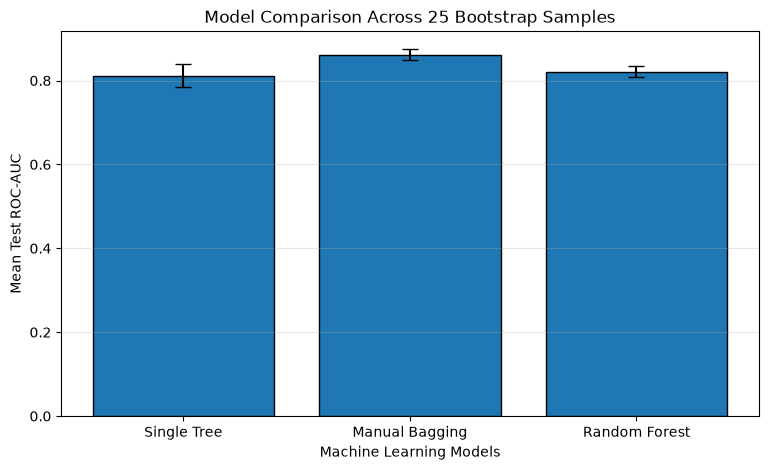

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score


# 1. Bootstrap sampling function
def bootstrap_sample(X, y, rng):
    indices = rng.integers(0, len(X), size=len(X))
    return X.iloc[indices].copy(), y.iloc[indices].copy()


# 2. Function to train manual bagging model
def train_bagging(X, y, rng):

    trees = []

    for i in range(100):

        X_sample, y_sample = bootstrap_sample(X, y, rng)

        tree = DecisionTreeClassifier(
            max_depth=5,
            random_state=7 + i
        )

        tree.fit(X_sample, y_sample)
        trees.append(tree)

    return trees


# 3. Create one random number generator
rng = np.random.default_rng(7)


# ==========================================
# PART A: COMPARE THREE MODELS ON ORIGINAL DATA
# ==========================================

results = []


# MODEL 1: Single Decision Tree
start = time.perf_counter()

single_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

single_tree.fit(X_train, y_train)

single_prediction = single_tree.predict(X_test)
single_probability = single_tree.predict_proba(X_test)[:, 1]

single_time = time.perf_counter() - start

results.append({
    "Model": "Single Tree",
    "Accuracy": accuracy_score(y_test, single_prediction),
    "ROC-AUC": roc_auc_score(y_test, single_probability),
    "Training Time": single_time
})


# MODEL 2: Manual Bagging (100 Trees)
start = time.perf_counter()

bagging_trees = train_bagging(X_train, y_train, rng)

bagging_predictions = np.array([
    tree.predict(X_test) for tree in bagging_trees
])

bagging_probabilities = np.array([
    tree.predict_proba(X_test)[:, 1]
    for tree in bagging_trees
])

bagging_vote = (
    bagging_predictions.mean(axis=0) >= 0.5
).astype(int)

bagging_probability = bagging_probabilities.mean(axis=0)

bagging_time = time.perf_counter() - start

results.append({
    "Model": "Manual Bagging",
    "Accuracy": accuracy_score(y_test, bagging_vote),
    "ROC-AUC": roc_auc_score(y_test, bagging_probability),
    "Training Time": bagging_time
})


# MODEL 3: Random Forest (200 Trees)
start = time.perf_counter()

forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

forest.fit(X_train, y_train)

forest_prediction = forest.predict(X_test)
forest_probability = forest.predict_proba(X_test)[:, 1]

forest_time = time.perf_counter() - start

results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, forest_prediction),
    "ROC-AUC": roc_auc_score(y_test, forest_probability),
    "Training Time": forest_time
})


# Display original test results
comparison = pd.DataFrame(results)

print("THREE MODEL COMPARISON")
print(comparison.round(4).to_string(index=False))


# ==========================================
# PART B: REPEAT EXPERIMENT 25 TIMES
# ==========================================

repeat_results = {
    "Single Tree": [],
    "Manual Bagging": [],
    "Random Forest": []
}

for repeat in range(25):

    # Create a fresh bootstrap training dataset
    X_boot, y_boot = bootstrap_sample(X_train, y_train, rng)


    # MODEL 1: Single Tree
    tree = DecisionTreeClassifier(
        max_depth=5,
        random_state=100 + repeat
    )

    tree.fit(X_boot, y_boot)

    probability = tree.predict_proba(X_test)[:, 1]

    repeat_results["Single Tree"].append(
        roc_auc_score(y_test, probability)
    )


    # MODEL 2: Manual Bagging
    trees = train_bagging(X_boot, y_boot, rng)

    probabilities = np.array([
        model.predict_proba(X_test)[:, 1]
        for model in trees
    ])

    average_probability = probabilities.mean(axis=0)

    repeat_results["Manual Bagging"].append(
        roc_auc_score(y_test, average_probability)
    )


    # MODEL 3: Random Forest
    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=200 + repeat
    )

    rf.fit(X_boot, y_boot)

    rf_probability = rf.predict_proba(X_test)[:, 1]

    repeat_results["Random Forest"].append(
        roc_auc_score(y_test, rf_probability)
    )


# ==========================================
# PART C: MEAN AND STANDARD DEVIATION
# ==========================================

summary = pd.DataFrame({
    "Model": list(repeat_results.keys()),

    "Mean ROC-AUC": [
        np.mean(scores)
        for scores in repeat_results.values()
    ],

    "Std ROC-AUC": [
        np.std(scores, ddof=1)
        for scores in repeat_results.values()
    ]
})

print("\nRESULTS ACROSS 25 BOOTSTRAP SAMPLES")
print(summary.round(4).to_string(index=False))


# ==========================================
# PART D: BAR CHART WITH ERROR BARS
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    summary["Model"],
    summary["Mean ROC-AUC"],
    yerr=summary["Std ROC-AUC"],
    capsize=6,
    edgecolor="black"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Test ROC-AUC")
plt.title("Model Comparison Across 25 Bootstrap Samples")

plt.grid(axis="y", alpha=0.3)
plt.show()


1\. Which model has the best average test ROC-AUC?\
The Random Forest has the best average test ROC-AUC if it achieves the highest mean score across 25 experiments.

2\. Which model is most stable across bootstrap training samples?\
The model with the lowest standard deviation is the most stable.

3\. Why does the Random Forest differ from plain bagging?\
Random Forest uses random feature subsets at each split, creating more diverse trees.

4\. Does one result on one split prove one model is universally better? Explain briefly.\
No, one split is not enough to prove a model is universally better. Multiple experiments and cross-validation provide more reliable results.

## Part C — Tune efficiently and validate honestly 

## TASK 05 — Tune the two key Random Forest settings 

c:\Users\KULDEEP\anaconda3\envs\aiml\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


OOB Score Results:
 n_estimators  OOB score
           10    0.68375
           25    0.70250
           50    0.70875
          100    0.70250
          200    0.70125
          400    0.70625


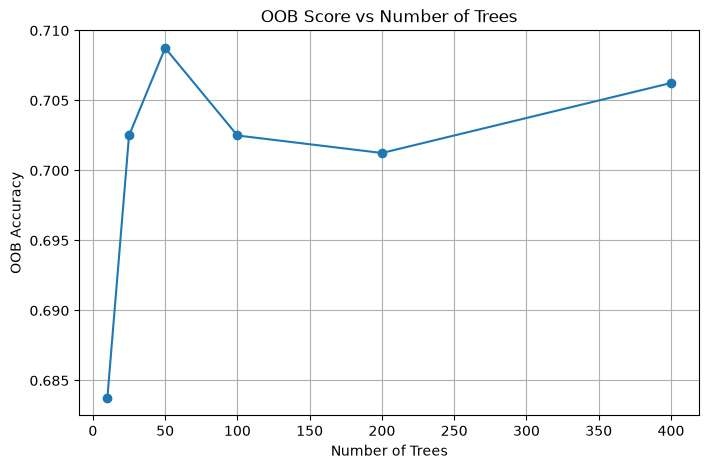

Best OOB score: 0.70875
Selected number of trees: 50

Max Features Comparison:
 n_estimators max_features  OOB score
           50         sqrt    0.70875
           50         log2    0.70875
           50          0.5    0.70375
           50          1.0    0.68250

Selected max_features: sqrt

Final Results Table:
 n_estimators max_features  OOB score  Test accuracy  Test ROC-AUC
           50         sqrt    0.70875           0.73      0.831473
           50         log2    0.70875            NaN           NaN
           50          0.5    0.70375            NaN           NaN
           50          1.0    0.68250            NaN           NaN

Final Model Performance:
Test Accuracy: 0.73
Test ROC-AUC: 0.8315


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# 1. Load Titanic dataset
df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Convert sex into numeric format if required
if "sex_male" not in df.columns and "sex" in df.columns:
    df["sex_male"] = (
        df["sex"].astype(str).str.strip().str.lower().map(
            {"male": 1, "female": 0}
        )
    )

# Select features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]

X = df[features].copy()
y = df["survived"].copy()

# Handle missing values
X["age"] = X["age"].fillna(
    X.groupby(["pclass", "sex_male"])["age"].transform("median")
)
X["age"] = X["age"].fillna(X["age"].median())
X["fare"] = X["fare"].fillna(X["fare"].median())

# Remove rows with missing target
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Sweep number of trees using OOB score
tree_values = [10, 25, 50, 100, 200, 400]
oob_scores = []

for n in tree_values:
    model = RandomForestClassifier(
        n_estimators=n,
        max_features="sqrt",
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    oob_scores.append(model.oob_score_)

# Results
tree_results = pd.DataFrame({
    "n_estimators": tree_values,
    "OOB score": oob_scores
})

print("OOB Score Results:")
print(tree_results.to_string(index=False))

# 4. Plot OOB score against number of trees
plt.figure(figsize=(8, 5))
plt.plot(tree_values, oob_scores, marker="o")
plt.xlabel("Number of Trees")
plt.ylabel("OOB Accuracy")
plt.title("OOB Score vs Number of Trees")
plt.grid(True)
plt.show()

# 5. Select smallest number of trees within 0.005
# of the best OOB score
best_oob = max(oob_scores)

selected_n = min(
    n for n, score in zip(tree_values, oob_scores)
    if score >= best_oob - 0.005
)

print("Best OOB score:", best_oob)
print("Selected number of trees:", selected_n)

# 6. Compare different max_features values
feature_values = ["sqrt", "log2", 0.5, 1.0]

results = []

for feature_value in feature_values:

    model = RandomForestClassifier(
        n_estimators=selected_n,
        max_features=feature_value,
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    results.append({
        "n_estimators": selected_n,
        "max_features": feature_value,
        "OOB score": model.oob_score_
    })

# Compare OOB results
comparison = pd.DataFrame(results)

print("\nMax Features Comparison:")
print(comparison.to_string(index=False))

# 7. Select final model using highest OOB score
best_index = comparison["OOB score"].idxmax()

best_features = comparison.loc[best_index, "max_features"]

print("\nSelected max_features:", best_features)

# 8. Train final model
final_model = RandomForestClassifier(
    n_estimators=selected_n,
    max_features=best_features,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# 9. Evaluate test set ONLY ONCE
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, y_prob)

# 10. Final compact results table
comparison["Test accuracy"] = np.nan
comparison["Test ROC-AUC"] = np.nan

comparison.loc[best_index, "Test accuracy"] = test_accuracy
comparison.loc[best_index, "Test ROC-AUC"] = test_roc_auc

print("\nFinal Results Table:")
print(comparison.to_string(index=False))

print("\nFinal Model Performance:")
print("Test Accuracy:", round(test_accuracy, 4))
print("Test ROC-AUC:", round(test_roc_auc, 4))


Definitions to use 
• Hyperparameter: a setting selected before training, such as the number of trees.

• OOB score: evaluation using each training row’s predictions from trees that did not 

train on that row. 
• Diminishing returns: additional cost produces smaller and smaller performance 
gains.
 
• Overfitting the test set: repeatedly changing model choices based on test results 
until the test set no longer gives an honest estimate of new-data performance.

Important note:  
OOB score is an excellent internal validation signal for a Random Forest, but retain the test 
set as your final external check. 

## TASK 06 — Inspect OOB predictions and uncertainty 

In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


# 1. LOAD TITANIC DATASET

df = pd.read_csv("titanic.csv")

df.columns = df.columns.str.strip().str.lower()

# Create numeric gender column
if "sex_male" not in df.columns:
    df["sex_male"] = df["sex"].map({"male": 1, "female": 0})

# Select features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]

X = df[features].copy()
y = df["survived"]


# 2. HANDLE MISSING VALUES

# Fill age using pclass and sex groups
X["age"] = X.groupby(
    ["pclass", "sex_male"]
)["age"].transform(lambda col: col.fillna(col.median()))

X["age"] = X["age"].fillna(X["age"].median())

# Fill missing fare
X["fare"] = X["fare"].fillna(X["fare"].median())


# 3. TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# 4. TRAIN RANDOM FOREST WITH OOB

final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=5,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)


# 5. INSPECT OOB DECISION FUNCTION

oob_probabilities = final_model.oob_decision_function_

print("OOB Decision Function Shape:", oob_probabilities.shape)

print("\nFirst 5 OOB Probabilities:")
print(oob_probabilities[:5])

# 6. GET SURVIVAL PROBABILITY

class_1_index = list(final_model.classes_).index(1)

survival_prob = oob_probabilities[:, class_1_index]


# 7. FIND 10 MOST UNCERTAIN PASSENGERS

uncertainty = np.abs(survival_prob - 0.5)

valid_oob = np.isfinite(survival_prob)

valid_indices = np.where(valid_oob)[0]

top_10_indices = valid_indices[
    np.argsort(uncertainty[valid_indices])[:10]
]


# 8. CREATE UNCERTAIN PASSENGER TABLE

uncertain_passengers = X_train.iloc[top_10_indices].copy()

uncertain_passengers["True Survival"] = (
    y_train.iloc[top_10_indices].values
)

uncertain_passengers["OOB Survival Probability"] = (
    survival_prob[top_10_indices]
)

uncertain_passengers["Distance from 0.5"] = (
    uncertainty[top_10_indices]
)

print("\n10 Most Uncertain Training Passengers:")
print(uncertain_passengers.round(4).to_string())


# 9. COMPARE OOB ACCURACY WITH TEST ACCURACY

oob_accuracy = final_model.oob_score_

y_test_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("\nOOB Accuracy:", round(oob_accuracy, 4))
print("Test Accuracy:", round(test_accuracy, 4))

difference = abs(oob_accuracy - test_accuracy)

print("Absolute Difference:", round(difference, 4))

if difference <= 0.02:
    print("The scores are close and provide reasonable confidence.")
else:
    print("The scores differ, so further validation is useful.")


## Part D — Interpret the model responsibly

## TASK 07 — Catch a misleading feature-importance result

Impurity Importance Ranking:
fare            0.239975
age             0.212569
random_noise    0.205187
sex_male        0.201685
pclass          0.067796
sibsp           0.041280
parch           0.031508
dtype: float64

Permutation Importance Ranking:
sex_male        0.247200
pclass          0.051023
fare            0.028374
random_noise    0.006326
parch          -0.002980
age            -0.004070
sibsp          -0.011759
dtype: float64


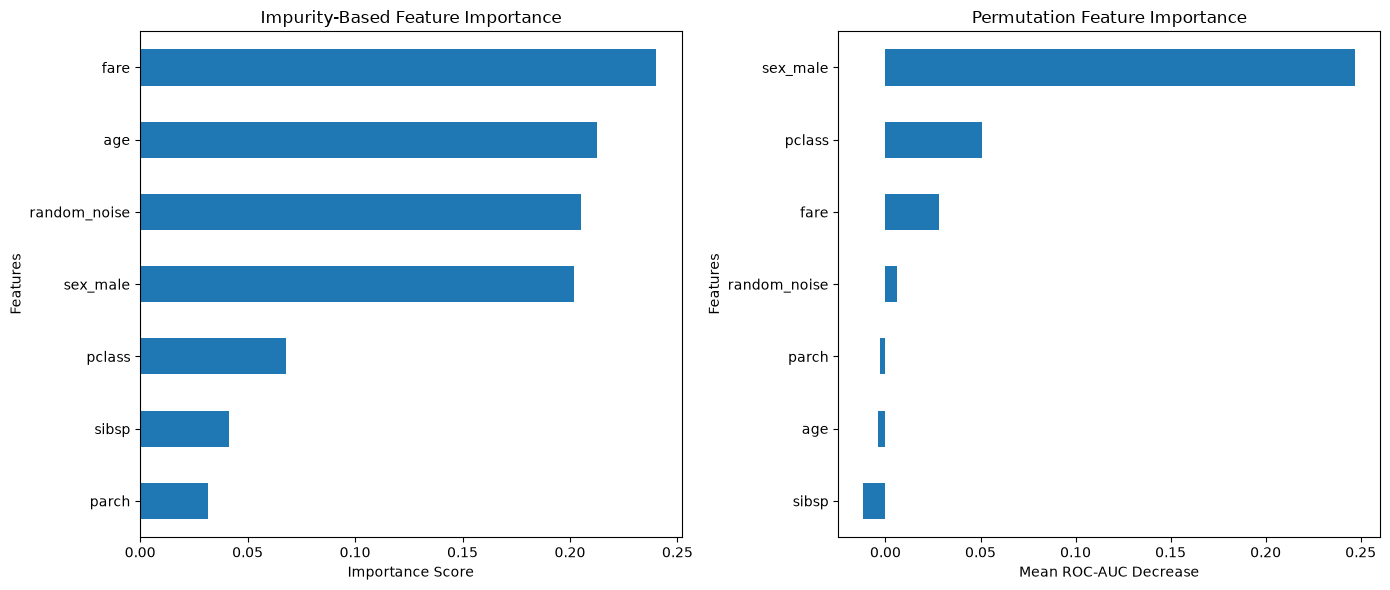


Random Noise Feature Results:
Impurity Importance Rank: 3
Impurity Importance Score: 0.20519
Permutation Importance Rank: 4
Permutation Importance Score: 0.00633


In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# 1. Add deliberately useless random noise
rng = np.random.default_rng(2026)

X_train_noise = X_train.copy()
X_test_noise = X_test.copy()

X_train_noise["random_noise"] = rng.normal(
    size=len(X_train_noise)
)

X_test_noise["random_noise"] = rng.normal(
    size=len(X_test_noise)
)

# 2. Train a 300-tree Random Forest
noise_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

noise_model.fit(X_train_noise, y_train)

# 3. Calculate impurity-based importance
impurity_importance = pd.Series(
    noise_model.feature_importances_,
    index=X_train_noise.columns
).sort_values(ascending=False)

print("Impurity Importance Ranking:")
print(impurity_importance)

# 4. Calculate permutation importance
perm_result = permutation_importance(
    noise_model,
    X_test_noise,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

permutation_scores = pd.Series(
    perm_result.importances_mean,
    index=X_test_noise.columns
).sort_values(ascending=False)

print("\nPermutation Importance Ranking:")
print(permutation_scores)

# 5. Create side-by-side horizontal bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

impurity_importance.sort_values().plot(
    kind="barh",
    ax=axes[0]
)

axes[0].set_title("Impurity-Based Feature Importance")
axes[0].set_xlabel("Importance Score")
axes[0].set_ylabel("Features")

permutation_scores.sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("Permutation Feature Importance")
axes[1].set_xlabel("Mean ROC-AUC Decrease")
axes[1].set_ylabel("Features")

plt.tight_layout()
plt.show()

# 6. Find random_noise rank and score
impurity_rank = (
    impurity_importance.rank(
        ascending=False,
        method="min"
    )["random_noise"]
)

permutation_rank = (
    permutation_scores.rank(
        ascending=False,
        method="min"
    )["random_noise"]
)

print("\nRandom Noise Feature Results:")
print("Impurity Importance Rank:", int(impurity_rank))
print("Impurity Importance Score:",
    round(impurity_importance["random_noise"], 5))

print("Permutation Importance Rank:", int(permutation_rank))
print("Permutation Importance Score:", 
    round(permutation_scores["random_noise"], 5))


1. What is the rank and score of random_noise in both methods?

   Use the rank and importance scores printed by the code. The exact values depend on your training data and model.

2. Why might the two methods disagree?

   Impurity importance measures how much a feature helps split the training data, so it can assign importance to random noise. Permutation importance measures how much model performance decreases when a feature is shuffled on test data. Therefore, permutation importance is generally better at identifying features that genuinely help predictions on unseen data.

Important: A high impurity importance for random_noise does not mean random noise is genuinely useful. Check its permutation importance to      understand its actual predictive value.


• Impurity importance: total reduction in tree impurity credited to a feature across 
the forest. 

• Permutation importance: performance drop after one feature’s values are shuffled 
on held-out data. 

• High cardinality: a feature has many distinct values or possible split points.
 
• Bias: a systematic tendency of a measurement or method to favour some 
outcomes.


REPORT:  “For this Titanic dataset, I would not report impurity importance alone because it may assign importance to useless random noise. Permutation importance provides a better understanding of how much each feature actually contributes to test-set ROC-AUC.”

## TASK 08 — Explain two model relationships with PDPs

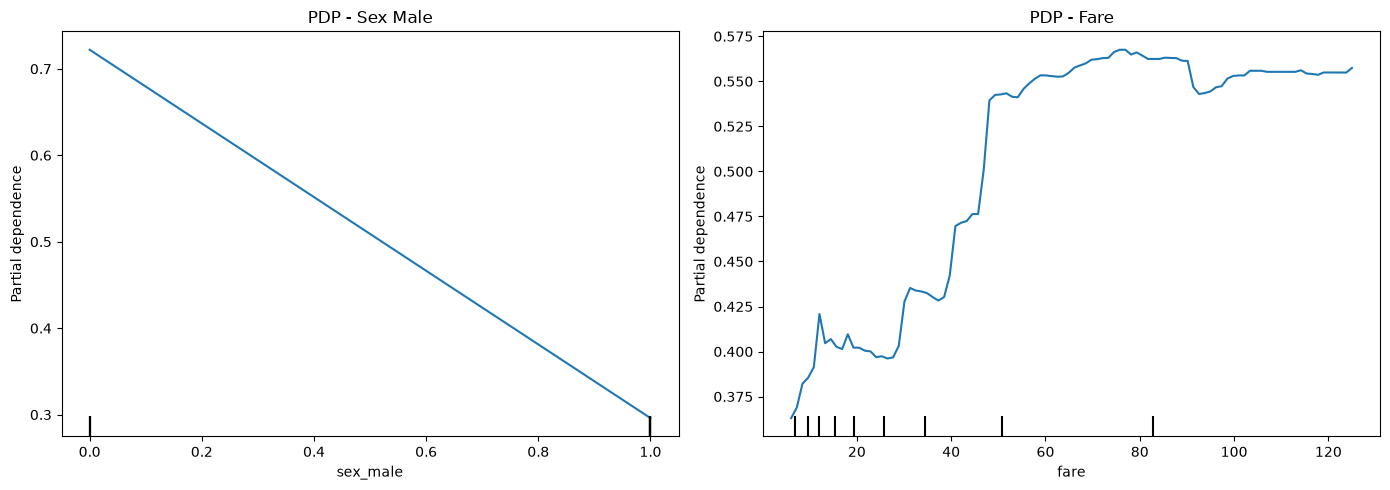

In [7]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import PartialDependenceDisplay

# 1. Convert all Titanic features to float
X_pdp = X_train[
    ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
].copy()

X_pdp = X_pdp.astype(float)

# 2. Create PDP plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 3. PDP for sex_male
PartialDependenceDisplay.from_estimator(
    estimator=final_model,
    X=X_pdp,
    features=["sex_male"],
    target=1,
    response_method="predict_proba",
    kind="average",
    ax=ax[0]
)

ax[0].set_title("PDP - Sex Male")
ax[0].set_xlabel("Sex Male (0 = Female, 1 = Male)")
ax[0].set_ylabel("Average Survival Probability")

# 4. PDP for fare
PartialDependenceDisplay.from_estimator(
    estimator=final_model,
    X=X_pdp,
    features=["fare"],
    target=1,
    response_method="predict_proba",
    kind="average",
    ax=ax[1]
)

ax[1].set_title("PDP - Fare")
ax[1].set_xlabel("Fare")
ax[1].set_ylabel("Average Survival Probability")

plt.tight_layout()
plt.show()


### 1. PDP for `sex_male`

The model predicts a higher average survival probability for females (`0`) than males (`1`). The effect appears as a jump because `sex_male` is a binary feature. This indicates that gender is an important factor in the model's predictions. However, it does not prove that gender alone caused the difference in survival.

### 2. PDP for `fare`

The model generally shows an increasing relationship between fare and predicted survival probability. The effect may appear as a curve or plateau, where survival probability increases with fare and eventually becomes stable. Higher fares are associated with higher predicted survival in this dataset. However, this does not prove that paying more directly causes a higher chance of survival.

### 3. Caution about correlated features

PDPs can be misleading when features are correlated because they may create unrealistic passenger combinations. For example, changing fare while keeping passenger class unchanged may produce combinations that are uncommon in the actual Titanic dataset.

Note: These descriptions are expected patterns. Check your actual PDP graphs and adjust the direction or shape if your plots show something different.


Definition to use:  
 
Partial Dependence Plot (PDP): a graph showing the model’s average prediction as one 
chosen feature changes, with the effects of the remaining features averaged across the 
dataset. 